# 11 처음 듣는 단어가 왜 새는가, 그리고 확신도 기준

10에서 기준선 A(Whisper 고정 + Linear)는 "명령 아님" 단어를 전부 쓰면 들은 단어는 더 잘 걸렀지만(오작동 2.27% → 0.69%) 처음 듣는 단어 흉내에서는 더 많이 샜습니다(17.04% → 31.83%, E18 → E19). 팀 모델 B(CNN)는 18% 안팎으로 그대로였습니다(09). 여기서는 그 원인을 확인하고, "명령 아님" 단어를 학습하지 않고 확신도로 거르는 방법과 비교합니다.

| 번호 | 실험 | 확인하려는 것 |
|---|---|---|
| E22 | Whisper, "명령 아님" 단어마다 153 / 600 / 1,400 / 전부, 4묶음 | 데이터가 늘수록 처음 듣는 단어 오작동이 꾸준히 오르는가 (들은 단어를 외우는가) |
| E23 | Whisper 특징 위에 Linear 대신 작은 MLP(512 → 256 → 11), 153 / 전부, 4묶음 | Linear 하나라서 "명령 아님" 영역을 넓게 못 잡는가 (MLP면 줄어드는가) |
| E24 | Whisper, 전부 + 클래스 가중치("명령 아님" 가중치 합을 153개 수준으로), 4묶음 | 비율 때문인가, 녹음 종류(외우기) 때문인가 |
| 분석 | 처음 듣는 단어 녹음마다 Whisper 특징이 가장 가까운 학습 녹음의 단어 | Whisper 특징이 발음으로 묶여 있는가 (one 옆에 on이 있는가) |
| E26 | 확신도 기준: "명령 아님" 학습 방식 4가지를 같은 놓침(2%, 5%, 10%)에서 비교. Whisper와 CNN | 명령어만 학습하고 확신도로 거르는 게 나은가, "명령 아님" 단어 학습이 도움인가 노이즈인가 |

E26의 학습 방식 4가지

| 방식 | "명령 아님"으로 학습하는 것 | 처음 듣는 단어로 보는 것 |
|---|---|---|
| 11클래스 · 전부 | 다른 단어(한 묶음 뺀 15개)의 녹음 전부 + 잡음 | 뺀 5개 단어 (4묶음) |
| 11클래스 · 153 | 다른 단어 15개 × 153개 + 잡음 | 뺀 5개 단어 (4묶음) |
| 명령어 + 잡음 | 잡음 구간만 | 다른 단어 20개 전부 |
| 명령어만 (10클래스) | 없음 | 다른 단어 20개 전부 |

- 확신도: 명령어 10개 중 가장 높은 확률. 이 값이 기준 t보다 낮거나 "명령 아님" 확률이 더 높으면 "명령 아님"으로 판정합니다.
- 기준 t는 **검증 명령어 녹음의 놓침률**만 보고 정합니다(놓침 ≤ 2%, 5%, 10%가 되는 가장 큰 t). 처음 듣는 단어 결과는 t를 정하는 데 쓰지 않습니다.
- 처음 듣는 단어 오작동은 단어 20개가 모두 한 번씩 포함되도록 4묶음을 합쳐서 셉니다. 그래서 네 방식 모두 같은 검증 녹음(5,580개)으로 비교됩니다.
- 에폭은 지금까지처럼 처음 듣는 단어로 보는 녹음을 뺀 검증 매크로 F1로 고릅니다. 시험 묶음은 쓰지 않습니다.
- Whisper 특징은 10에서 Drive에 저장한 것을 다시 씁니다(`USE_DRIVE = True`). CNN은 E26에서만 학습합니다.

In [1]:
# 셀 1. 설정과 버전
import os, sys, time, random, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import transformers
from transformers import WhisperProcessor, WhisperModel
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 몇 개만, 2에폭 (결과 숫자는 쓰지 않음)
USE_DRIVE = True               # True: Drive에 저장한 07의 Whisper 특징을 다시 쓰고, 새로 뽑은 특징도 Drive에 저장 (Colab)
SEEDS = [0, 1]                 # 모든 실험
CONDS = {"E15": 153, "E16": None}   # 09와 같음 (셀 2가 출력에 씀)
LEVELS = {"153": 153, "600": 600, "1400": 1400, "전부": None}   # E22: "명령 아님" 단어마다 학습 녹음 수
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # 09와 같음
B_CHANNELS = [16, 32, 64, 128]
WHISPER = "openai/whisper-base"
N_KEEP = 50                                       # 07과 같음: 인코더 출력 앞 50칸(1초) 평균
LIN_EPOCHS, LIN_LR, LIN_BATCH = 30, 1e-3, 512     # 07과 같음

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
DTYPE = torch.float16 if AMP else torch.float32
if SMOKE:
    B_EPOCHS = LIN_EPOCHS = 2
    CONDS = {"E15": 3, "E16": None}
    LEVELS = {"153": 3, "600": 6, "1400": 10, "전부": None}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| transformers", transformers.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | transformers 5.22.1 | pandas 2.2.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 /content/drive/MyDrive/DL_T02_cache


In [2]:
# 셀 2. 데이터 (09와 같은 구성, 같은 4묶음)
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서: 07에서 쓴 153개가 먼저
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
TRAIN_WORD = train_all.word.to_numpy(copy=True)
VAL_WORD = val.word.to_numpy(copy=True)

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(n, held):
    keep_n = (train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))
    return (keep_n & ~train_all.word.isin(held)).to_numpy(copy=True)

for f, held in enumerate(FOLDS):
    print(f"묶음 {f + 1}: 학습에서 뺄 단어 {held}")
    for eid, n in CONDS.items():
        m = train_mask(n, held)
        k = int((Y_ALL[torch.from_numpy(m)] == L2I[OTHER]).sum())
        print(f"   {eid} (단어마다 {n if n else '전부'}): 학습 {m.sum():,}개, '명령 아님' {k:,}개 ({k / m.sum():.1%}), "
              f"검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

100%|██████████| 2.26G/2.26G [00:25<00:00, 93.9MB/s]


묶음 1: 학습에서 뺄 단어 ['four', 'six', 'two', 'cat', 'wow']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,469개
   E16 (단어마다 전부): 학습 66,857개, '명령 아님' 36,088개 (54.0%), 검증에서 뺀 단어 1,469개
묶음 2: 학습에서 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,502개
   E16 (단어마다 전부): 학습 66,560개, '명령 아님' 35,791개 (53.8%), 검증에서 뺀 단어 1,502개
묶음 3: 학습에서 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,331개
   E16 (단어마다 전부): 학습 68,339개, '명령 아님' 37,570개 (55.0%), 검증에서 뺀 단어 1,331개
묶음 4: 학습에서 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,278개
   E16 (단어마다 전부): 학습 68,189개, '명령 아님' 37,420개 (54.9%), 검증에서 뺀 단어 1,278개


In [3]:
# 셀 3. 소리 읽기 → 로그 멜 (07·08과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def spec(df, name):
    def run():
        M, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]           # 08과 같은 이름·순서 → 저장된 게 있으면 다시 씀
MEL_VAL = spec(val, "spec09_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

# Whisper 특징: 07과 같은 행 순서(목록 파일의 학습 묶음 = 단어마다 153개)와 같은 방법
wtrain = base_train.reset_index(drop=True)
if SMOKE:
    wtrain = wtrain.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
Y_W = torch.tensor(wtrain.label.map(L2I).values)
W_WORD = wtrain.word.to_numpy(copy=True)

def whisper_feats(df, name):
    def run():
        fe = WhisperProcessor.from_pretrained(WHISPER).feature_extractor
        whisper = WhisperModel.from_pretrained(WHISPER, torch_dtype=DTYPE).to(device).eval()
        X, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=32, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                f = fe(list(x), sampling_rate=SR, return_tensors="pt").input_features.to(device, DTYPE)
                hs = whisper.encoder(f, output_hidden_states=True).hidden_states[1:]
                X.append(torch.stack([h[:, :N_KEEP].mean(1) for h in hs], 1).half().cpu())
        d = {"X": torch.cat(X), "sec": time.time() - t0}
        print(f"  {name}: {tuple(d['X'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

WX_TR = whisper_feats(wtrain, "whisper10_train" if SMOKE else "whisper_base11_train")["X"][:, -1]   # 마지막 층 (07의 E08과 같음)
WX_VA = whisper_feats(val, "whisper10_val" if SMOKE else "whisper_base11_val")["X"][:, -1]
assert len(WX_TR) == len(wtrain) and len(WX_VA) == len(val)
print("Whisper 학습 특징", tuple(WX_TR.shape), "| 검증", tuple(WX_VA.shape))

# B와 같은 학습 데이터(train_all: 명령어 + 잡음 + "명령 아님" 단어 전부)의 Whisper 특징.
# 07에서 저장한 34,829개는 그대로 쓰고, 없는 녹음(추가된 "명령 아님" 단어)만 새로 뽑음
def keys(df):
    return list(zip(df.path, df.start.astype(int), df.gain.astype(float).round(6)))
W_IDX = {k: i for i, k in enumerate(keys(wtrain))}
src = [W_IDX.get(k, -1) for k in keys(train_all)]
have = torch.tensor([j >= 0 for j in src])
extra_df = train_all[~have.numpy()].reset_index(drop=True)
print(f"B와 같은 학습 데이터 {len(train_all):,}개 중 07에서 저장한 것 {int(have.sum()):,}개, 새로 뽑을 것 {len(extra_df):,}개")
WX_EXTRA = whisper_feats(extra_df, "whisper10_extra" if SMOKE else "whisper_base11_extra")["X"][:, -1]
WX_ALL = torch.empty(len(train_all), WX_TR.shape[1], dtype=WX_TR.dtype)
WX_ALL[have] = WX_TR[[j for j in src if j >= 0]]
WX_ALL[~have] = WX_EXTRA
print("Whisper 학습 특징 (B와 같은 데이터)", tuple(WX_ALL.shape))

  spec08_train_pool: 저장된 것 사용 (처음 계산 55초)
  spec11_val: 저장된 것 사용 (처음 계산 10초)
  whisper_base11_train: 저장된 것 사용 (처음 계산 1365초)
  whisper_base11_val: 저장된 것 사용 (처음 계산 375초)
Whisper 학습 특징 (34829, 512) | 검증 (9400, 512)
B와 같은 학습 데이터 79,392개 중 07에서 저장한 것 34,829개, 새로 뽑을 것 44,563개
  whisper_base11_extra: 저장된 것 사용 (처음 계산 1620초)
Whisper 학습 특징 (B와 같은 데이터) (79392, 512)


In [4]:
# 셀 4. 평가 함수, 팀 모델 B(09와 같은 CNN), Whisper 위 Linear(07과 같은 설정). 에폭은 뺀 단어를 제외한 검증 F1로 고름
def evaluate(pred, held):
    """held: 학습에서 뺀 단어. 지표를 뺀 단어 / 남은 단어 / 잡음으로 나눠 계산"""
    p, t = pred.cpu().numpy(), Y_VAL.numpy()
    oth = L2I[OTHER]
    is_held = np.isin(VAL_WORD, held)
    sel = ~is_held                                           # 에폭 선택용: 뺀 단어 제외
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    is_cmd = t != oth
    known = (val.group.values == "seen_other") & ~is_held
    noise = val.group.values == "noise"
    return {"f1": float(f1.mean()), "acc": float(tp.sum() / cm.sum()),
            "fa_held": float(np.mean(p[is_held] != oth)) if is_held.any() else float("nan"),
            "fa_known": float(np.mean(p[known] != oth)),
            "fa_noise": float(np.mean(p[noise] != oth)) if noise.any() else float("nan"),
            "miss": float(np.mean(p[is_cmd] == oth)),
            "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))),
            "pred": p}

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, held):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"loss": tot / len(Xtr), "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    return best, pd.DataFrame(hist)

def fit_linear(held, seed, Xtr=None, Ytr=None, words=None):
    """07의 E08과 같은 Linear. held 단어를 학습에서 빼고, 뺀 단어를 제외한 검증 F1로 에폭을 고름"""
    Xtr = WX_TR if Xtr is None else Xtr
    Ytr = Y_W if Ytr is None else Ytr
    words = W_WORD if words is None else words
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(~np.isin(words, held))
    X = Xtr[m].float().to(device); Y = Ytr[m].to(device)
    mu, sd = X.mean(0), X.std(0) + 1e-6
    X, Xva = (X - mu) / sd, (WX_VA.float().to(device) - mu) / sd
    head = nn.Linear(X.shape[1], K).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=LIN_LR)
    best, t0 = None, time.time()
    for ep in range(LIN_EPOCHS):
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), LIN_BATCH):
            idx = perm[i:i + LIN_BATCH]
            loss = nn.functional.cross_entropy(head(X[idx]), Y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            pred = head(Xva).argmax(1)
        r = evaluate(pred, held)
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    best["sec"] = time.time() - t0
    best["n_train"] = int(m.sum())
    return best

def word_fa(pred, w):
    """검증 묶음에서 단어 w의 녹음 중 명령으로 판정된 비율"""
    mw = VAL_WORD == w
    return float(np.mean(pred[mw] != L2I[OTHER]))

In [5]:
# 셀 5. 학습 함수: Whisper 위 머리(Linear 또는 MLP)와 CNN. 둘 다 검증 확률(softmax)을 돌려줌
# 출력이 10개(명령어만)면 "명령 아님" 열은 0으로 채워 11열로 맞춤
def to_prob11(logits, n_out):
    p = torch.softmax(logits.float(), 1)
    if n_out == 10:
        p = torch.cat([p, torch.zeros(len(p), 1, device=p.device)], 1)
    return p

def train_head(mask, held, seed, n_out=K, hidden=0, w_other=1.0):
    """WX_ALL(B와 같은 학습 데이터의 Whisper 마지막 층 특징)에서 mask 행으로 머리를 학습. 07과 같은 설정(Adam 1e-3, 배치 512, 30에폭)"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    X = WX_ALL[m].float().to(device); Y = Y_ALL[m].to(device)
    assert n_out == K or int(Y.max()) < n_out
    mu, sd = X.mean(0), X.std(0) + 1e-6
    X, Xva = (X - mu) / sd, (WX_VA.float().to(device) - mu) / sd
    head = (nn.Linear(X.shape[1], n_out) if hidden == 0 else
            nn.Sequential(nn.Linear(X.shape[1], hidden), nn.ReLU(), nn.Linear(hidden, n_out))).to(device)
    cw = torch.ones(n_out, device=device)
    if n_out == K:
        cw[L2I[OTHER]] = w_other
    opt = torch.optim.Adam(head.parameters(), lr=LIN_LR)
    best = None
    for ep in range(LIN_EPOCHS):
        head.train()
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), LIN_BATCH):
            idx = perm[i:i + LIN_BATCH]
            loss = nn.functional.cross_entropy(head(X[idx]), Y[idx], weight=cw)
            opt.zero_grad(); loss.backward(); opt.step()
        head.eval()
        with torch.no_grad():
            logits = head(Xva)
        r = evaluate(logits.argmax(1), held)
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1, "prob": to_prob11(logits, n_out).cpu().numpy()}
    best["n_train"] = int(m.sum())
    best["mu_sd"] = (mu.cpu(), sd.cpu())
    return best

def train_cnn_prob(mask, held, seed, n_out=K):
    """09의 train_cnn과 같은 학습(20에폭, Adam 1e-3, 배치 256). 출력 수를 바꿀 수 있고 검증 확률을 돌려줌"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    assert n_out == K or int(Ytr.max()) < n_out
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN(n_classes=n_out).to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, t0 = None, time.time()
    for ep in range(B_EPOCHS):
        cnn.train()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            logits = torch.cat([cnn(Xva[i:i + 1024]) for i in range(0, len(Xva), 1024)])
        r = evaluate(logits.argmax(1), held)
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1, "prob": to_prob11(logits, n_out).cpu().numpy()}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["n_train"] = int(m.sum()); best["sec"] = time.time() - t0
    return best

IS_OTHER_WORD = (train_all.group == "seen_other").to_numpy(copy=True)
IS_NOISE = (train_all.group == "noise").to_numpy(copy=True)
ALL_WORDS = sorted(DIGITS + AUX)
def summary(runs, name):
    d = pd.DataFrame([{k: r[k] for k in ["f1", "fa_held", "fa_known", "fa_noise", "miss", "confuse"]} for r in runs])
    print(f"  {name}: F1 {d.f1.mean():.4f} ± {d.f1.std():.4f} | 오작동 뺀 단어 {d.fa_held.mean():.2%} ± {d.fa_held.std():.2%} · "
          f"남은 단어 {d.fa_known.mean():.2%} · 잡음 {d.fa_noise.mean():.2%} | 놓침 {d.miss.mean():.2%} | 명령 혼동 {d.confuse.mean():.2%}")
    return d

In [6]:
# 셀 6. E22 Whisper "명령 아님" 데이터 양 153 / 600 / 1,400 / 전부, 4묶음 × 시드 2개 (Linear)
E22 = {}
t0 = time.time()
for name, n in LEVELS.items():
    E22[name] = []
    for f, held in enumerate(FOLDS):
        for seed in SEEDS:
            b = train_head(train_mask(n, held), held, seed)
            b.update({"묶음": f + 1, "시드": seed, "held": held}); E22[name].append(b)
print(f"E22 ({time.time() - t0:.0f}초) 4묶음 × 시드 2개 = 8번 평균")
for name, runs in E22.items():
    summary(runs, f"단어마다 {name:>4} (학습 약 {np.mean([r['n_train'] for r in runs]):,.0f}개)")
print("  묶음별 뺀 단어 오작동 (시드 평균):")
for name, runs in E22.items():
    print(f"    {name:>4}: " + " | ".join(f"묶음 {f + 1} {np.mean([r['fa_held'] for r in runs if r['묶음'] == f + 1]):.2%}" for f in range(len(FOLDS))))
print("참고 (10 결과): E18(153) 뺀 단어 17.04%, E19(전부) 31.83%. 셀 4의 evaluate와 같은 규칙이라 153·전부는 같은 값이 나와야 함")

E22 (113초) 4묶음 × 시드 2개 = 8번 평균
  단어마다  153 (학습 약 34,064개): F1 0.9700 ± 0.0008 | 오작동 뺀 단어 16.94% ± 6.02% · 남은 단어 2.32% · 잡음 0.00% | 놓침 0.52% | 명령 혼동 1.61%
  단어마다  600 (학습 약 40,769개): F1 0.9764 ± 0.0012 | 오작동 뺀 단어 16.28% ± 4.69% · 남은 단어 1.15% · 잡음 0.00% | 놓침 1.12% | 명령 혼동 1.28%
  단어마다 1400 (학습 약 52,769개): F1 0.9780 ± 0.0010 | 오작동 뺀 단어 25.23% ± 10.04% · 남은 단어 0.77% · 잡음 0.00% | 놓침 1.50% | 명령 혼동 1.13%
  단어마다   전부 (학습 약 67,486개): F1 0.9780 ± 0.0007 | 오작동 뺀 단어 31.83% ± 11.51% · 남은 단어 0.69% · 잡음 0.00% | 놓침 1.76% | 명령 혼동 1.02%
  묶음별 뺀 단어 오작동 (시드 평균):
     153: 묶음 1 15.15% | 묶음 2 13.95% | 묶음 3 12.21% | 묶음 4 26.45%
     600: 묶음 1 13.21% | 묶음 2 13.08% | 묶음 3 15.44% | 묶음 4 23.40%
    1400: 묶음 1 18.72% | 묶음 2 14.55% | 묶음 3 29.15% | 묶음 4 38.50%
      전부: 묶음 1 24.13% | 묶음 2 21.74% | 묶음 3 32.27% | 묶음 4 49.18%
참고 (10 결과): E18(153) 뺀 단어 17.04%, E19(전부) 31.83%. 셀 4의 evaluate와 같은 규칙이라 153·전부는 같은 값이 나와야 함


In [7]:
# 셀 7. E23 Whisper 특징 위 MLP(512 → 256 → 11) · E24 전부 + 클래스 가중치, 4묶음 × 시드 2개
E23 = {name: [] for name in ["153", "전부"]}
E24 = []
for f, held in enumerate(FOLDS):
    for seed in SEEDS:
        for name in E23:
            b = train_head(train_mask(LEVELS[name], held), held, seed, hidden=256)
            b.update({"묶음": f + 1, "시드": seed, "held": held}); E23[name].append(b)
        m_all, m_153 = train_mask(None, held), train_mask(LEVELS["153"], held)
        w = (m_153 & (IS_OTHER_WORD | IS_NOISE)).sum() / (m_all & (IS_OTHER_WORD | IS_NOISE)).sum()   # "명령 아님" 가중치 합을 153개 수준으로
        b = train_head(m_all, held, seed, w_other=float(w))
        b.update({"묶음": f + 1, "시드": seed, "held": held, "w": float(w)}); E24.append(b)
print("4묶음 × 시드 2개 = 8번 평균")
summary(E22["153"], "Linear · 153      (E22)")
summary(E23["153"], "MLP    · 153      (E23)")
summary(E22["전부"], "Linear · 전부     (E22)")
summary(E23["전부"], "MLP    · 전부     (E23)")
summary(E24, f"Linear · 전부 + 가중치 {np.mean([r['w'] for r in E24]):.4f} (E24)")
print("읽는 법: MLP·전부가 Linear·전부보다 크게 낮으면 Linear의 한계, 가중치를 줘도 높으면 비율이 아니라 녹음 종류(외우기) 때문")

4묶음 × 시드 2개 = 8번 평균
  Linear · 153      (E22): F1 0.9700 ± 0.0008 | 오작동 뺀 단어 16.94% ± 6.02% · 남은 단어 2.32% · 잡음 0.00% | 놓침 0.52% | 명령 혼동 1.61%
  MLP    · 153      (E23): F1 0.9708 ± 0.0014 | 오작동 뺀 단어 13.27% ± 5.28% · 남은 단어 2.15% · 잡음 0.00% | 놓침 0.61% | 명령 혼동 1.59%
  Linear · 전부     (E22): F1 0.9780 ± 0.0007 | 오작동 뺀 단어 31.83% ± 11.51% · 남은 단어 0.69% · 잡음 0.00% | 놓침 1.76% | 명령 혼동 1.02%
  MLP    · 전부     (E23): F1 0.9798 ± 0.0009 | 오작동 뺀 단어 9.29% ± 6.18% · 남은 단어 0.47% · 잡음 0.00% | 놓침 1.67% | 명령 혼동 1.01%
  Linear · 전부 + 가중치 0.0898 (E24): F1 0.9705 ± 0.0012 | 오작동 뺀 단어 40.34% ± 13.27% · 남은 단어 2.15% · 잡음 2.35% | 놓침 0.62% | 명령 혼동 1.57%
읽는 법: MLP·전부가 Linear·전부보다 크게 낮으면 Linear의 한계, 가중치를 줘도 높으면 비율이 아니라 녹음 종류(외우기) 때문


In [8]:
# 셀 8. 분석: 처음 듣는 단어 녹음마다, Whisper 특징(학습 묶음 기준으로 표준화)이 가장 가까운(코사인) 학습 녹음의 단어
# 4묶음마다 그 묶음의 학습 녹음(전부 조건)과 비교. 학습 녹음은 명령어, 남은 15개 단어, 잡음
nn_rows = []
for f, held in enumerate(FOLDS):
    m = train_mask(None, held)
    Xt = WX_ALL[torch.from_numpy(m)].float().to(device)
    mu, sd = Xt.mean(0), Xt.std(0) + 1e-6
    Xt = nn.functional.normalize((Xt - mu) / sd, dim=1)
    wt = TRAIN_WORD[m]
    hv = np.where(np.isin(VAL_WORD, held))[0]
    Xv = nn.functional.normalize((WX_VA[hv].float().to(device) - mu) / sd, dim=1)
    idx = torch.cat([(Xv[i:i + 512] @ Xt.T).argmax(1) for i in range(0, len(Xv), 512)]).cpu().numpy()
    for v, j in zip(hv, idx):
        nn_rows.append({"단어": VAL_WORD[v], "가장 가까운 단어": wt[j]})
    del Xt
nnd = pd.DataFrame(nn_rows)
nnd["명령어"] = nnd["가장 가까운 단어"].isin(COMMANDS)
tab = nnd.groupby("단어").agg(녹음=("명령어", "size"), 이웃이_명령어=("명령어", "mean"))
tab["가장 많은 이웃 단어 3개"] = nnd.groupby("단어")["가장 가까운 단어"].apply(
    lambda s: ", ".join(f"{w} {c / len(s):.0%}" for w, c in s.value_counts().head(3).items()))
e19_fa = {w: np.mean([word_fa(r["pred"] if "pred" in r else r["prob"][:, :10].argmax(1), w) for r in E22["전부"] if w in r["held"]]) for w in ALL_WORDS}
tab["Whisper 전부 오작동 (E22)"] = [e19_fa[w] for w in tab.index]
tab = tab.sort_values("Whisper 전부 오작동 (E22)", ascending=False)
print(tab.to_string(formatters={"이웃이_명령어": "{:.0%}".format, "Whisper 전부 오작동 (E22)": "{:.1%}".format}))
print(f"\n뺀 단어 녹음 중 가장 가까운 학습 녹음이 명령어인 비율: {nnd['명령어'].mean():.1%} (전체 {len(nnd):,}개)")
r = np.corrcoef(tab["이웃이_명령어"], tab["Whisper 전부 오작동 (E22)"])[0, 1]
print(f"단어 20개에서 '이웃이 명령어인 비율'과 '오작동'의 상관계수: {r:.2f}")

         녹음 이웃이_명령어                  가장 많은 이웃 단어 3개 Whisper 전부 오작동 (E22)
단어                                                                      
house   195     83%        off 60%, yes 18%, wow 6%                91.3%
dog     197     37%     bed 37%, bird 21%, down 18%                86.0%
one     351     85%          on 81%, wow 8%, two 2%                72.1%
wow     193     58%       one 34%, no 31%, down 13%                66.8%
nine    356     30%      one 32%, eight 21%, no 20%                65.3%
eight   346     62%    right 52%, three 13%, bed 9%                52.6%
zero    384     33%   seven 28%, go 23%, sheila 10%                43.4%
five    367     29%     nine 51%, right 21%, six 9%                34.1%
four    373     39%    three 20%, one 18%, five 15%                26.4%
two     345     52%     go 48%, three 20%, zero 17%                24.3%
cat     180     58%       left 29%, bed 27%, go 11%                23.3%
marvin  195      5%     bird 49%, nine 17%, one 13%

In [9]:
# 셀 9. E26 확신도 기준: "명령 아님" 학습 방식 4가지 × Whisper·CNN, 같은 놓침에서 처음 듣는 단어 오작동 비교
TARGETS = [None, 0.02, 0.05, 0.10]
TS = np.linspace(0, 1, 1001)
y_val, oth = Y_VAL.numpy(), L2I[OTHER]
is_cmd_val = y_val != oth
g_val = val.group.values

def curve(prob, held):
    """기준 t마다 놓침, 명령 혼동, 오작동(처음 듣는 단어로 보는 녹음 / 들은 단어 / 잡음)의 개수"""
    pc = prob[:, :10]; c = pc.argmax(1); s = pc.max(1)
    keep = prob[:, oth] < s                                      # "명령 아님" 확률이 더 높으면 거름
    is_held = np.isin(VAL_WORD, held); known = (g_val == "seen_other") & ~is_held; noise = g_val == "noise"
    rows = []
    for t in TS:
        acc = keep & (s >= t)
        rows.append({"t": t, "miss": np.mean(~acc[is_cmd_val]), "confuse": np.mean(acc[is_cmd_val] & (c[is_cmd_val] != y_val[is_cmd_val])),
                     "held_acc": int(acc[is_held].sum()), "held_n": int(is_held.sum()),
                     "known_acc": int(acc[known].sum()), "known_n": int(known.sum()), "noise_acc": int(acc[noise].sum()), "noise_n": int(noise.sum())})
    return pd.DataFrame(rows)

def at_target(cv, m):
    if m is None:
        return cv.iloc[0]
    ok = cv[cv.miss <= m]
    return ok.iloc[-1] if len(ok) else None                    # 놓침 ≤ m 안에서 가장 엄격한 t

def pooled(runs_by_seed):
    """시드마다 4묶음(또는 1개)의 개수를 합쳐 비율로, 그다음 시드 평균"""
    out = {}
    for m in TARGETS:
        per_seed = []
        for runs in runs_by_seed:
            pts = [at_target(curve(r["prob"], r["held"]), m) for r in runs]
            if any(p is None for p in pts):
                per_seed.append(None); continue
            per_seed.append({"t": np.mean([p.t for p in pts]), "miss": np.mean([p.miss for p in pts]), "confuse": np.mean([p.confuse for p in pts]),
                             "fa_held": sum(p.held_acc for p in pts) / sum(p.held_n for p in pts),
                             "fa_known": (sum(p.known_acc for p in pts) / sum(p.known_n for p in pts)) if sum(p.known_n for p in pts) else float("nan"),
                             "fa_noise": sum(p.noise_acc for p in pts) / max(1, sum(p.noise_n for p in pts))})
        out[m] = None if any(p is None for p in per_seed) else {k: np.mean([p[k] for p in per_seed]) for k in per_seed[0]}
    return out

CMD_ONLY = (~IS_OTHER_WORD) & (~IS_NOISE)                       # 명령어 녹음만
CMD_NOISE = ~IS_OTHER_WORD                                      # 명령어 + 잡음
methods = {}
# Whisper: 11클래스 두 가지는 E22 결과(4묶음)를 그대로, 나머지는 새로 학습 (다른 단어 20개 전부가 처음 듣는 단어)
methods[("Whisper", "11클래스 · 전부")] = [[r for r in E22["전부"] if r["시드"] == s] for s in SEEDS]
methods[("Whisper", "11클래스 · 153")] = [[r for r in E22["153"] if r["시드"] == s] for s in SEEDS]
methods[("Whisper", "명령어 + 잡음")] = [[{**train_head(CMD_NOISE.copy(), ALL_WORDS, s), "held": ALL_WORDS}] for s in SEEDS]
methods[("Whisper", "명령어만 (10클래스)")] = [[{**train_head(CMD_ONLY.copy(), ALL_WORDS, s, n_out=10), "held": ALL_WORDS}] for s in SEEDS]
# CNN: 11클래스 · 전부는 4묶음을 다시 학습(확률이 필요해서), 나머지 두 방식은 한 번씩
t0 = time.time()
methods[("CNN", "11클래스 · 전부")] = [[{**train_cnn_prob(train_mask(None, held), held, s), "held": held} for held in FOLDS] for s in SEEDS]
methods[("CNN", "명령어 + 잡음")] = [[{**train_cnn_prob(CMD_NOISE.copy(), ALL_WORDS, s), "held": ALL_WORDS}] for s in SEEDS]
methods[("CNN", "명령어만 (10클래스)")] = [[{**train_cnn_prob(CMD_ONLY.copy(), ALL_WORDS, s, n_out=10), "held": ALL_WORDS}] for s in SEEDS]
print(f"CNN 학습 {time.time() - t0:.0f}초")

res = {k: pooled(v) for k, v in methods.items()}
rows = []
for (model, how), out in res.items():
    for m in TARGETS:
        o = out[m]
        label = "기준 없음" if m is None else f"놓침 ≤ {m:.0%}"
        if o is None:
            rows.append({"모델": model, "학습 방식": how, "조건": label, "기준 t": "도달 불가"}); continue
        rows.append({"모델": model, "학습 방식": how, "조건": label, "기준 t": f"{o['t']:.3f}", "놓침": f"{o['miss']:.2%}",
                     "오작동(처음 듣는 단어)": f"{o['fa_held']:.2%}", "오작동(들은 단어)": "-" if np.isnan(o["fa_known"]) else f"{o['fa_known']:.2%}",
                     "오작동(잡음)": f"{o['fa_noise']:.2%}", "명령 혼동": f"{o['confuse']:.2%}"})
pd.set_option("display.width", 230)
print(pd.DataFrame(rows).to_string(index=False))
print("처음 듣는 단어: 11클래스는 4묶음에서 뺀 단어를 합친 것, 나머지는 다른 단어 20개 전부. 둘 다 같은 검증 녹음 5,580개. 시드 2개 평균")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 검증 {len(val):,}개")

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


CNN 학습 1434초
     모델        학습 방식       조건  기준 t    놓침 오작동(처음 듣는 단어) 오작동(들은 단어) 오작동(잡음) 명령 혼동
Whisper   11클래스 · 전부    기준 없음 0.000 1.76%        31.16%      0.69%   0.00% 1.02%
Whisper   11클래스 · 전부  놓침 ≤ 2% 0.427 2.00%        25.69%      0.54%   0.00% 0.92%
Whisper   11클래스 · 전부  놓침 ≤ 5% 0.849 4.98%         5.97%      0.10%   0.00% 0.19%
Whisper   11클래스 · 전부 놓침 ≤ 10% 0.984 9.91%         0.66%      0.03%   0.00% 0.00%
Whisper  11클래스 · 153    기준 없음 0.000 0.52%        16.71%      2.31%   0.00% 1.61%
Whisper  11클래스 · 153  놓침 ≤ 2% 0.582 2.00%         9.35%      1.21%   0.00% 0.88%
Whisper  11클래스 · 153  놓침 ≤ 5% 0.907 4.99%         1.88%      0.24%   0.00% 0.15%
Whisper  11클래스 · 153 놓침 ≤ 10% 0.991 9.87%         0.22%      0.04%   0.00% 0.00%
Whisper     명령어 + 잡음    기준 없음 0.000 0.03%        97.24%          -   0.00% 1.96%
Whisper     명령어 + 잡음  놓침 ≤ 2% 0.627 2.00%        46.12%          -   0.00% 0.86%
Whisper     명령어 + 잡음  놓침 ≤ 5% 0.933 4.98%         9.83%          -   0.00% 0.12%
Whisper     명령어

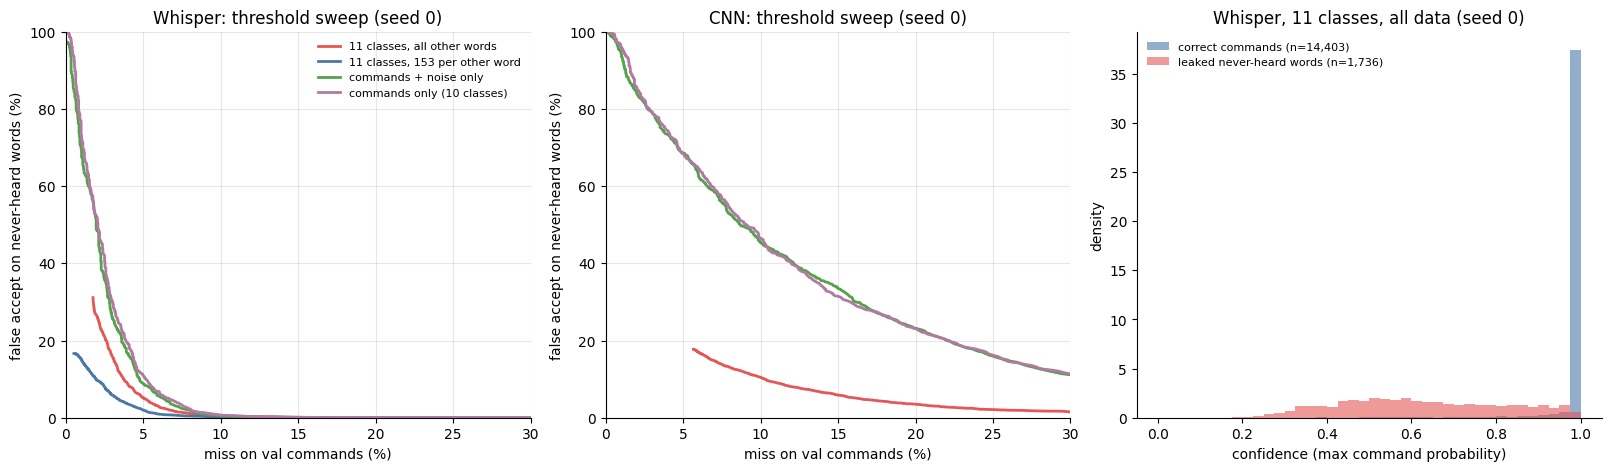

샌 처음 듣는 단어 중 확신도 0.9 이상: 10.0% | 맞힌 명령어 중 0.9 이상: 96.6%


In [10]:
# 셀 10. 그림: 놓침 대 처음 듣는 단어 오작동 곡선(기준 t를 0 → 1로), 시드 0. 그리고 Whisper 11클래스 · 전부의 확신도 분포
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
colors = {"11클래스 · 전부": "#E45756", "11클래스 · 153": "#4C78A8", "명령어 + 잡음": "#54A24B", "명령어만 (10클래스)": "#B279A2"}
EN = {"11클래스 · 전부": "11 classes, all other words", "11클래스 · 153": "11 classes, 153 per other word", "명령어 + 잡음": "commands + noise only", "명령어만 (10클래스)": "commands only (10 classes)"}
for a, model in zip(ax[:2], ["Whisper", "CNN"]):
    for (mdl, how), runs_by_seed in methods.items():
        if mdl != model:
            continue
        cvs = [curve(r["prob"], r["held"]) for r in runs_by_seed[0]]
        miss = np.mean([cv.miss.values for cv in cvs], 0)
        fa = sum(cv.held_acc.values for cv in cvs) / sum(cv.held_n.values for cv in cvs)
        a.plot(miss * 100, fa * 100, "-", lw=2, color=colors[how], label=EN[how])
    a.set_xlim(0, 30); a.set_ylim(0, 100)
    a.set_xlabel("miss on val commands (%)"); a.set_ylabel("false accept on never-heard words (%)")
    a.set_title(f"{model}: threshold sweep (seed 0)"); a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=8)
r0 = [r for r in E22["전부"] if r["시드"] == SEEDS[0]]
conf_cmd, conf_leak = [], []
for r in r0:
    p = r["prob"]; s = p[:, :10].max(1); c = p[:, :10].argmax(1); keep = p[:, oth] < s
    hm = np.isin(VAL_WORD, r["held"])
    conf_leak += list(s[hm & keep]); conf_cmd += list(s[is_cmd_val & keep & (c == y_val)])
bins = np.linspace(0, 1, 41)
ax[2].hist(conf_cmd, bins, density=True, alpha=.6, color="#4C78A8", label=f"correct commands (n={len(conf_cmd):,})")
ax[2].hist(conf_leak, bins, density=True, alpha=.6, color="#E45756", label=f"leaked never-heard words (n={len(conf_leak):,})")
ax[2].set_xlabel("confidence (max command probability)"); ax[2].set_ylabel("density"); ax[2].set_title("Whisper, 11 classes, all data (seed 0)")
ax[2].legend(frameon=False, fontsize=8); ax[2].spines[["top", "right"]].set_visible(False)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/11_threshold_curves.png", dpi=150)
plt.show()
if conf_leak and conf_cmd:
    print(f"샌 처음 듣는 단어 중 확신도 0.9 이상: {np.mean(np.array(conf_leak) >= 0.9):.1%} | 맞힌 명령어 중 0.9 이상: {np.mean(np.array(conf_cmd) >= 0.9):.1%}")